In [1]:
from pathlib import Path
import json
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

ROOT = Path.cwd().resolve()
if ROOT.name == "linear_regression":
    ROOT = ROOT.parent

TRAIN_FILE = ROOT / "data/processed/Hanoi_final.csv"
TEST_FILE = ROOT / "data/processed/Hanoi_test_final.csv"
OUT = ROOT / "linear_regression" / "ln_output"
OUT.mkdir(parents=True, exist_ok=True)

WINDOW = 24
TARGET = "temperature_2m"
SEED = 42
np.random.seed(SEED)

In [2]:
# Danh sách 32 features
weather_features = [
    "temperature_2m", "relative_humidity_2m", "dew_point_2m",
    "apparent_temperature", "precipitation", "rain", "pressure_msl",
    "surface_pressure", "cloud_cover", "wind_speed_10m", "wind_speed_100m",
    "wind_direction_10m_sin", "wind_direction_10m_cos",
    "wind_direction_100m_sin", "wind_direction_100m_cos", "wind_gusts_10m",
    "et0_fao_evapotranspiration", "vapour_pressure_deficit",
    "soil_temperature_0_to_7cm", "soil_temperature_7_to_28cm",
    "soil_temperature_28_to_100cm", "soil_temperature_100_to_255cm",
    "soil_moisture_0_to_7cm", "soil_moisture_7_to_28cm",
    "soil_moisture_28_to_100cm", "soil_moisture_100_to_255cm",
    "weather_code", "is_day",
]
features = weather_features + ["hour_sin", "hour_cos", "day_of_year_sin", "day_of_year_cos"]

In [3]:
# Đọc dữ liệu 
data = pd.read_csv(TRAIN_FILE , parse_dates = ['time']).sort_values('time').reset_index(drop = True)

values = data[features].to_numpy(dtype = np.float32)
temperature = data[TARGET].to_numpy(dtype = np.float32)

#Tạo Sliding Window
windows = sliding_window_view(values , WINDOW , axis = 0)[:-1]
windows = windows.transpose(0,2,1)[: , ::-1 , :]

X = windows.reshape(len(windows),-1).copy()
y = temperature[WINDOW:]

times = pd.DatetimeIndex(data['time'].iloc[WINDOW:])
baseline = temperature[WINDOW -1 : -1]


# Chia train / validation
train_count = (times < "2025-01-01").sum()
X_train, y_train = X[:train_count], y[:train_count]
X_valid, y_valid = X[train_count:], y[train_count:]
valid_baseline = baseline[train_count:]

print("Train:", X_train.shape, "| Validation:", X_valid.shape)

Train: (131448, 768) | Validation: (8760, 768)


In [4]:
def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    r2 = 1.0 - (np.sum((y_true - y_pred) ** 2) / (np.sum((y_true - np.mean(y_true)) ** 2) + 1e-12))
    return {"MAE": float(mae), "RMSE": float(rmse), "R2": float(r2)}

# Chuẩn hóa Z-score trực tiếp bằng biến NumPy (chỉ lấy mean, std từ X_train)
x_mean = np.mean(X_train, axis=0, dtype=np.float64)
x_std = np.std(X_train, axis=0, dtype=np.float64)
x_std[x_std < 1e-8] = 1.0  # Tránh chia cho 0

X_train_scaled = ((X_train - x_mean) / x_std).astype(np.float32)
X_valid_scaled = ((X_valid - x_mean) / x_std).astype(np.float32)

print("Persistence (validation):", evaluate(y_valid, valid_baseline))

Persistence (validation): {'MAE': 0.5569748978636581, 'RMSE': 0.8955298743336904, 'R2': 0.9737443307300588}


In [5]:
def train_linear_gd(X_tr, y_tr, X_val, y_val, l1=0.0, l2=0.0, lr=0.005, epochs=100, batch_size=2048, patience=10):
    N, D = X_tr.shape
    rng = np.random.default_rng(SEED)
    
    # Khởi tạo trọng số w = 0, hệ số chặn b = trung bình của y_tr
    w = np.zeros(D, dtype=np.float64)
    b = float(np.mean(y_tr))
    
    best_mae = float("inf")
    best_w, best_b = w.copy(), b
    best_epoch = 0
    wait = 0

    for epoch in range(1, epochs + 1):
        indices = rng.permutation(N)
        
        for start in range(0, N, batch_size):
            batch_idx = indices[start : start + batch_size]
            Xb = X_tr[batch_idx].astype(np.float64)
            yb = y_tr[batch_idx].astype(np.float64)
            m = len(batch_idx)

            # 1. Dự đoán & Tính sai số
            error = (Xb @ w + b) - yb

            # 2. Đạo hàm (MSE + L1 + L2)
            grad_w = (Xb.T @ error) / m + l1 * np.sign(w) + l2 * w
            grad_b = np.mean(error)

            # 3. Cập nhật w, b
            w -= lr * grad_w
            b -= lr * grad_b

        # Kiểm tra trên tập Validation cuối mỗi epoch
        val_preds = X_val @ w + b
        val_mae = np.mean(np.abs(y_val - val_preds))

        if val_mae < best_mae - 1e-5:
            best_mae = val_mae
            best_w, best_b = w.copy(), b
            best_epoch = epoch
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    return best_w.astype(np.float32), float(best_b), best_epoch

In [6]:
lr_configs = [
    {"name": "OLS", "l1": 0.0, "l2": 0.0},

    # Ridge
    {"name": "Ridge_L2_0.001", "l1": 0.0, "l2": 1e-3},
    {"name": "Ridge_L2_0.01", "l1": 0.0, "l2": 1e-2},

    # Lasso
    {"name": "Lasso_L1_0.0001", "l1": 1e-4, "l2": 0.0},
    {"name": "Lasso_L1_0.001", "l1": 1e-3, "l2": 0.0},

    # Elastic Net: sử dụng cả L1 và L2
    {"name": "Elastic_1", "l1": 1e-4, "l2": 1e-3},
    {"name": "Elastic_2", "l1": 1e-3, "l2": 1e-3},
    {"name": "Elastic_3", "l1": 1e-3, "l2": 1e-2},
    {"name": "Elastic_4", "l1": 1e-2, "l2": 1e-2},
]

lr_rows = []
saved_weights = {}  # Lưu trực tiếp cặp (w, b) của từng cấu hình

for i, cfg in enumerate(lr_configs):
    start = perf_counter()
    w, b, best_ep = train_linear_gd(
        X_train_scaled, y_train, 
        X_valid_scaled, y_valid, 
        l1=cfg["l1"], l2=cfg["l2"], lr=0.005, epochs=100
    )
    elapsed = perf_counter() - start
    
    # Dự đoán bằng công thức tuyến tính: X @ w + b
    val_preds = X_valid_scaled @ w + b
    score = evaluate(y_valid, val_preds)
    
    saved_weights[cfg["name"]] = (w, b)
    lr_rows.append({
        "config": cfg["name"], "l1": cfg["l1"], "l2": cfg["l2"],
        "best_epoch": best_ep, **score, "seconds": elapsed
    })
    print(f"[{i+1:02d}/{len(lr_configs)}] {cfg['name']:16s} | Val MAE={score['MAE']:.4f} | RMSE={score['RMSE']:.4f} | Ep={best_ep:3d} | {elapsed:.2f}s")

lr_results = pd.DataFrame(lr_rows).sort_values("MAE")
print(lr_results.to_string(index=False))

[01/9] OLS              | Val MAE=0.4123 | RMSE=0.5519 | Ep= 98 | 41.30s
[02/9] Ridge_L2_0.001   | Val MAE=0.4129 | RMSE=0.5526 | Ep= 98 | 42.15s
[03/9] Ridge_L2_0.01    | Val MAE=0.4184 | RMSE=0.5605 | Ep= 98 | 41.70s
[04/9] Lasso_L1_0.0001  | Val MAE=0.4123 | RMSE=0.5519 | Ep= 98 | 42.57s
[05/9] Lasso_L1_0.001   | Val MAE=0.4137 | RMSE=0.5548 | Ep= 98 | 40.75s
[06/9] Elastic_1        | Val MAE=0.4129 | RMSE=0.5527 | Ep= 98 | 42.96s
[07/9] Elastic_2        | Val MAE=0.4143 | RMSE=0.5557 | Ep= 98 | 42.32s
[08/9] Elastic_3        | Val MAE=0.4205 | RMSE=0.5643 | Ep= 98 | 41.52s
[09/9] Elastic_4        | Val MAE=0.4462 | RMSE=0.6045 | Ep= 96 | 40.64s
         config     l1    l2  best_epoch      MAE     RMSE       R2   seconds
Lasso_L1_0.0001 0.0001 0.000          98 0.412308 0.551921 0.990027 42.566701
            OLS 0.0000 0.000          98 0.412329 0.551853 0.990030 41.297672
      Elastic_1 0.0001 0.001          98 0.412867 0.552707 0.989999 42.961258
 Ridge_L2_0.001 0.0000 0.001   

In [7]:
from pathlib import Path
import numpy as np

# Xác định thư mục output
out_dir = Path("linear_regression/ln_output")

# Tạo thư mục nếu chưa tồn tại
out_dir.mkdir(parents=True, exist_ok=True)

# 1. Lưu kết quả đánh giá của 9 mô hình
lr_results.to_csv(out_dir / "lr_results.csv", index=False)

# 2. Lưu weights và bias của 9 mô hình
weights_data = {}

for name, (w, b) in saved_weights.items():
    weights_data[f"{name}_w"] = w
    weights_data[f"{name}_b"] = b

np.savez_compressed(
    out_dir / "lr_weights.npz",
    **weights_data
)

print(f"Saved results to: {out_dir.resolve()}")

Saved results to: /home/welcome/Weather-Forecasting-system-AIL/linear_regression/linear_regression/ln_output


In [8]:
# Chọn mô hình tốt nhất trong 9 mô hình theo Validation MAE
ranking = lr_results.sort_values("MAE").reset_index(drop=True)

print("=== VALIDATION RANKING ===")
print(ranking.to_string(index=False))

best_row = ranking.iloc[0]
best_name = best_row["config"]

# Lấy weights và bias của mô hình tốt nhất
w_best, b_best = saved_weights[best_name]

print(f"\nBest Model: {best_name}")
print(f"Validation MAE: {best_row['MAE']:.4f}")
print(f"Validation RMSE: {best_row['RMSE']:.4f}")

# Đọc và tạo cửa sổ trượt cho tập Test 2026
test = pd.read_csv(TEST_FILE, parse_dates=["time"]).sort_values("time").reset_index(drop=True)
combined = pd.concat([data.tail(WINDOW), test], ignore_index=True)

values_test = combined[features].to_numpy(dtype=np.float32)
temp_test = combined[TARGET].to_numpy(dtype=np.float32)

windows_test = sliding_window_view(values_test, WINDOW, axis=0)[:-1]
windows_test = windows_test.transpose(0, 2, 1)[:, ::-1, :]

X_test = windows_test.reshape(len(windows_test), -1).copy()
y_test = temp_test[WINDOW:]
persistence = temp_test[WINDOW - 1:-1]

# Chuẩn hóa X_test bằng x_mean và x_std của tập Train
X_test_scaled = ((X_test - x_mean) / x_std).astype(np.float32)

# Dự đoán bằng mô hình tốt nhất
pred_best = X_test_scaled @ w_best + b_best

# Bảng kết quả Test
test_results = pd.DataFrame([
    {"model": "Persistence", **evaluate(y_test, persistence)},
    {"model": f"Best Model ({best_name})", **evaluate(y_test, pred_best)},
]).sort_values("MAE")

print("\n=== TEST RESULTS ===")
print(test_results.to_string(index=False))

=== VALIDATION RANKING ===
         config     l1    l2  best_epoch      MAE     RMSE       R2   seconds
Lasso_L1_0.0001 0.0001 0.000          98 0.412308 0.551921 0.990027 42.566701
            OLS 0.0000 0.000          98 0.412329 0.551853 0.990030 41.297672
      Elastic_1 0.0001 0.001          98 0.412867 0.552707 0.989999 42.961258
 Ridge_L2_0.001 0.0000 0.001          98 0.412879 0.552620 0.990002 42.145027
 Lasso_L1_0.001 0.0010 0.000          98 0.413691 0.554767 0.989924 40.754344
      Elastic_2 0.0010 0.001          98 0.414302 0.555656 0.989892 42.323332
  Ridge_L2_0.01 0.0000 0.010          98 0.418433 0.560472 0.989716 41.698511
      Elastic_3 0.0010 0.010          98 0.420481 0.564252 0.989577 41.521173
      Elastic_4 0.0100 0.010          96 0.446246 0.604492 0.988037 40.638318

Best Model: Lasso_L1_0.0001
Validation MAE: 0.4123
Validation RMSE: 0.5519

=== TEST RESULTS ===
                       model      MAE     RMSE       R2
Best Model (Lasso_L1_0.0001) 0.487632 0

=== ERROR ANALYSIS ===
                       model    Bias  Std Error    MAE   RMSE  P95 Absolute Error  Max Absolute Error
Best Model (Lasso_L1_0.0001) -0.0179     0.6633 0.4876 0.6636              1.3555              3.6783
                 Persistence  0.0013     0.9396 0.5841 0.9396              2.3000              5.6000

=== MONTHLY ERROR ANALYSIS ===
            MAE    Bias  Std_Error
month                             
2026-01  0.4670 -0.0434     0.6077
2026-02  0.4222  0.0150     0.5483
2026-03  0.4558 -0.0162     0.6197
2026-04  0.5372 -0.0757     0.7152
2026-05  0.4649 -0.0037     0.6482
2026-06  0.5451 -0.0225     0.7344
2026-07  0.4693 -0.0399     0.6345
2026-08  0.5001 -0.0061     0.6980
2026-09  0.5266  0.0358     0.7352


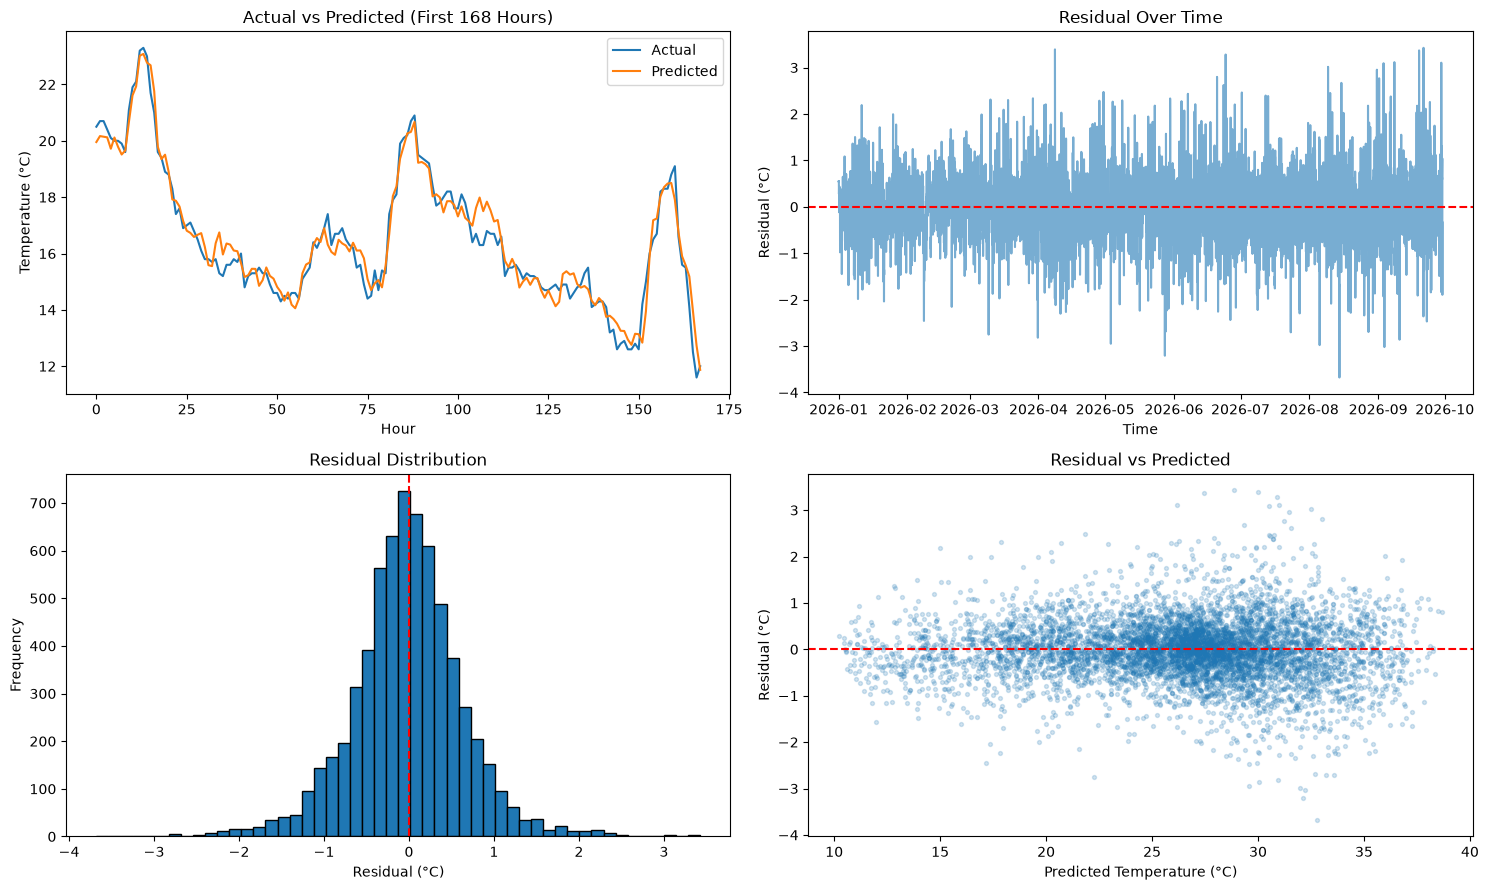

In [9]:
# Tính sai số dự đoán: Residual = Actual - Predicted
residual = y_test - pred_best
residual_base = y_test - persistence

# Thống kê sai số
error_analysis = pd.DataFrame([
    {
        "model": f"Best Model ({best_name})",
        "Bias": np.mean(residual),
        "Std Error": np.std(residual),
        "MAE": np.mean(np.abs(residual)),
        "RMSE": np.sqrt(np.mean(residual**2)),
        "P95 Absolute Error": np.percentile(np.abs(residual), 95),
        "Max Absolute Error": np.max(np.abs(residual))
    },
    {
        "model": "Persistence",
        "Bias": np.mean(residual_base),
        "Std Error": np.std(residual_base),
        "MAE": np.mean(np.abs(residual_base)),
        "RMSE": np.sqrt(np.mean(residual_base**2)),
        "P95 Absolute Error": np.percentile(np.abs(residual_base), 95),
        "Max Absolute Error": np.max(np.abs(residual_base))
    }
])

print("=== ERROR ANALYSIS ===")
print(error_analysis.round(4).to_string(index=False))

# Phân tích sai số theo từng tháng
error_df = pd.DataFrame({
    "time": test["time"],
    "actual": y_test,
    "predicted": pred_best,
    "residual": residual,
    "absolute_error": np.abs(residual)
})

error_df["month"] = error_df["time"].dt.to_period("M")

monthly_error = error_df.groupby("month").agg(
    MAE=("absolute_error", "mean"),
    Bias=("residual", "mean"),
    Std_Error=("residual", "std")
)

print("\n=== MONTHLY ERROR ANALYSIS ===")
print(monthly_error.round(4).to_string())

# Vẽ biểu đồ phân tích
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Actual vs Predicted - 168 giờ đầu tiên
n = min(168, len(y_test))

axes[0, 0].plot(y_test[:n], label="Actual")
axes[0, 0].plot(pred_best[:n], label="Predicted")
axes[0, 0].set_title("Actual vs Predicted (First 168 Hours)")
axes[0, 0].set_xlabel("Hour")
axes[0, 0].set_ylabel("Temperature (°C)")
axes[0, 0].legend()

# Residual theo thời gian
axes[0, 1].plot(test["time"], residual, alpha=0.6)
axes[0, 1].axhline(0, color="red", linestyle="--")
axes[0, 1].set_title("Residual Over Time")
axes[0, 1].set_xlabel("Time")
axes[0, 1].set_ylabel("Residual (°C)")

# Phân bố sai số
axes[1, 0].hist(residual, bins=50, edgecolor="black")
axes[1, 0].axvline(0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Distribution")
axes[1, 0].set_xlabel("Residual (°C)")
axes[1, 0].set_ylabel("Frequency")

# Sai số theo giá trị dự đoán
axes[1, 1].scatter(pred_best, residual, alpha=0.2, s=8)
axes[1, 1].axhline(0, color="red", linestyle="--")
axes[1, 1].set_title("Residual vs Predicted")
axes[1, 1].set_xlabel("Predicted Temperature (°C)")
axes[1, 1].set_ylabel("Residual (°C)")

plt.tight_layout()
plt.show()

=== FEATURE IMPORTANCE ===
                      feature  importance  importance_pct
               temperature_2m      3.4960         13.8780
         apparent_temperature      2.4521          9.7340
                       is_day      2.3683          9.4012
         relative_humidity_2m      2.1663          8.5995
      vapour_pressure_deficit      2.0592          8.1742
                 dew_point_2m      2.0451          8.1182
    soil_temperature_0_to_7cm      1.7674          7.0159
   et0_fao_evapotranspiration      1.5272          6.0626
             surface_pressure      0.8705          3.4556
                 pressure_msl      0.8663          3.4388
              wind_speed_100m      0.8032          3.1884
   soil_temperature_7_to_28cm      0.6407          2.5434
               wind_speed_10m      0.5668          2.2502
               wind_gusts_10m      0.4963          1.9701
 soil_temperature_28_to_100cm      0.4294          1.7045
       wind_direction_10m_cos      0.3829    

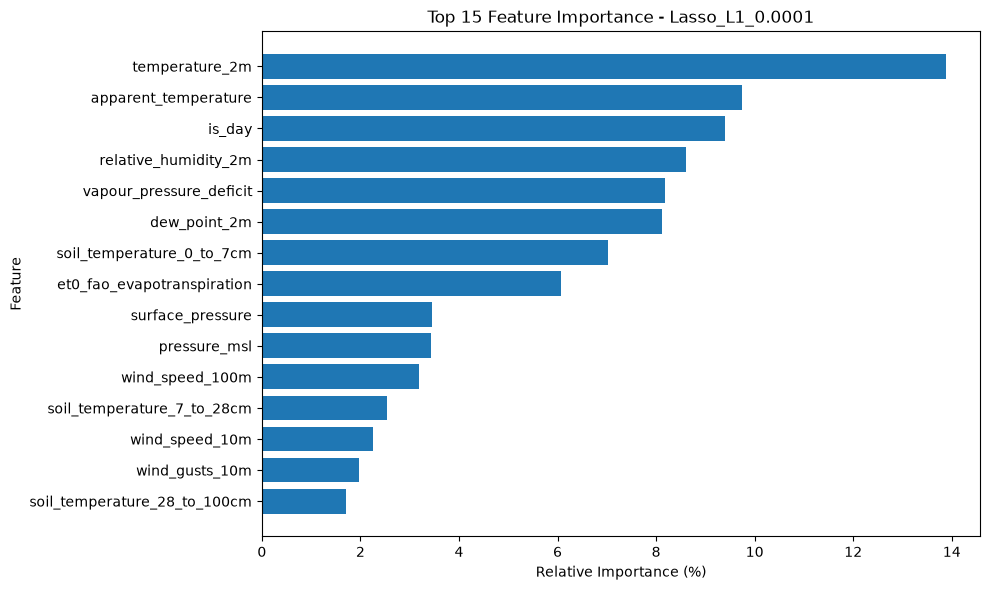

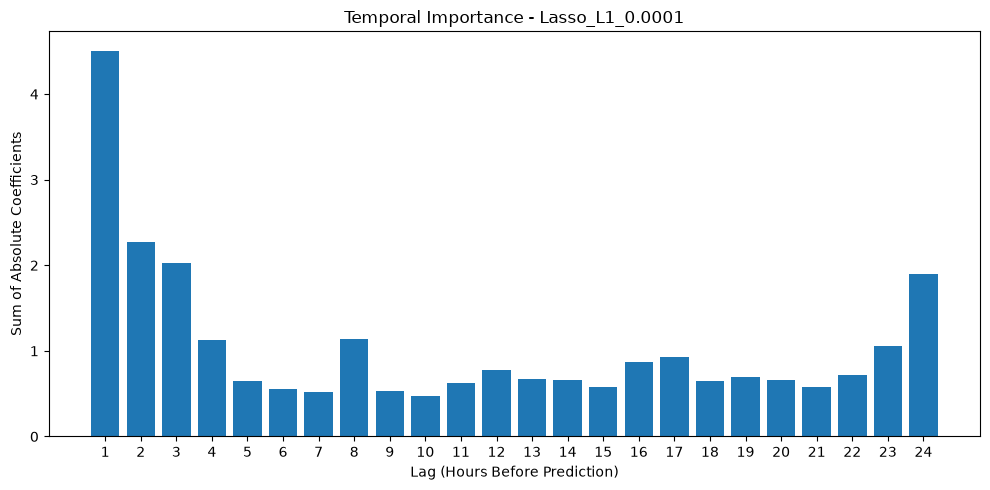

In [10]:
# ==================================================
# 1. Feature Importance từ hệ số Linear Regression
# ==================================================

# Mỗi feature có WINDOW hệ số tương ứng 24 giờ
weights = np.asarray(w_best).reshape(WINDOW, len(features))

# Tổng trị tuyệt đối hệ số theo từng feature
importance = np.sum(np.abs(weights), axis=0)

# Chuẩn hóa về phần trăm
importance_pct = (
    importance / importance.sum() * 100
    if importance.sum() > 0
    else np.zeros_like(importance)
)

feature_importance = pd.DataFrame({
    "feature": features,
    "importance": importance,
    "importance_pct": importance_pct
}).sort_values("importance", ascending=False)

print("=== FEATURE IMPORTANCE ===")
print(feature_importance.round(4).to_string(index=False))


# ==================================================
# 2. Vẽ Feature Importance
# ==================================================

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["feature"][::-1],
    top_features["importance_pct"][::-1]
)

plt.xlabel("Relative Importance (%)")
plt.ylabel("Feature")
plt.title(f"Top 15 Feature Importance - {best_name}")
plt.tight_layout()
plt.show()


# ==================================================
# 3. Phân tích mức độ quan trọng theo từng giờ Lag
# ==================================================

# Do dữ liệu Test đảo thứ tự thời gian [:, ::-1, :]
# Lag 1 là giờ gần nhất, Lag 24 là giờ xa nhất
lag_importance = np.abs(weights).sum(axis=1)

lag_df = pd.DataFrame({
    "lag": np.arange(1, WINDOW + 1),
    "importance": lag_importance
})

plt.figure(figsize=(10, 5))
plt.bar(lag_df["lag"], lag_df["importance"])
plt.xlabel("Lag (Hours Before Prediction)")
plt.ylabel("Sum of Absolute Coefficients")
plt.title(f"Temporal Importance - {best_name}")
plt.xticks(np.arange(1, WINDOW + 1))
plt.tight_layout()
plt.show()